In [1]:
import sys

sys.argv = [""]  # to avoid issues with Jupyter and argparse

In [2]:
import numpyro

numpyro.set_host_device_count(4)
import jax
import jax.numpy as jnp
import arviz as az
import xarray
from scipy.stats import qmc
from ipywidgets import interact, IntSlider
import matplotlib.pyplot as plt

In [46]:
from HSA_Cam_D_005 import (
    predict_Mo1,
    predict_Mo4,
    JSD_marginal,
    JSD_between_predictions,
    calculate_disagreement,
    LHSDOE,
    generate_synthetic_data,
    run_inference_Mo1,
    run_inference_Mo4,
    find_opt_candidate,
)

In [4]:
initial_proposals = LHSDOE(32)
T = initial_proposals[:, 0:1]
p = initial_proposals[:, 1:2]
c2h = initial_proposals[:, 2:3]
c2m = initial_proposals[:, 3:4]
c2w = initial_proposals[:, 4:5]
c2i = initial_proposals[:, 5:6]
# generatte synthetic observations
T_obs, p_obs, r_obs = generate_synthetic_data(
    T,
    p,
    c2h,
    c2m,
    c2w,
    c2i,
    seed=42,
    rel_noise_std=0.1,
)

In [5]:
# Run both models
Mo1_idata = run_inference_Mo1(
    T_obs,
    p_obs,
    r_obs,
    num_samples=1000,
    num_warmup=250,
    progressbar=True,
)
Mo4_idata = run_inference_Mo4(
    T_obs,
    p_obs,
    r_obs,
    num_samples=1000,
    num_warmup=250,
    progressbar=True,
)

Starting MCMC: 4 chains × (250 warmup + 1000 samples)


  0%|          | 0/1250 [00:00<?, ?it/s]

  0%|          | 0/1250 [00:00<?, ?it/s]

  0%|          | 0/1250 [00:00<?, ?it/s]

  0%|          | 0/1250 [00:00<?, ?it/s]

...

  0%|          | 0/1250 [00:00<?, ?it/s]

  0%|          | 0/1250 [00:00<?, ?it/s]

  0%|          | 0/1250 [00:00<?, ?it/s]

  0%|          | 0/1250 [00:00<?, ?it/s]

MCMC sampling completed successfully!


array([[<Axes: title={'center': 'k0'}>, <Axes: title={'center': 'k0'}>],
       [<Axes: title={'center': 'Ea_k'}>,
        <Axes: title={'center': 'Ea_k'}>],
       [<Axes: title={'center': 'k_deact'}>,
        <Axes: title={'center': 'k_deact'}>],
       [<Axes: title={'center': 'Ea_deact'}>,
        <Axes: title={'center': 'Ea_deact'}>],
       [<Axes: title={'center': 'sigma_r'}>,
        <Axes: title={'center': 'sigma_r'}>]], dtype=object)

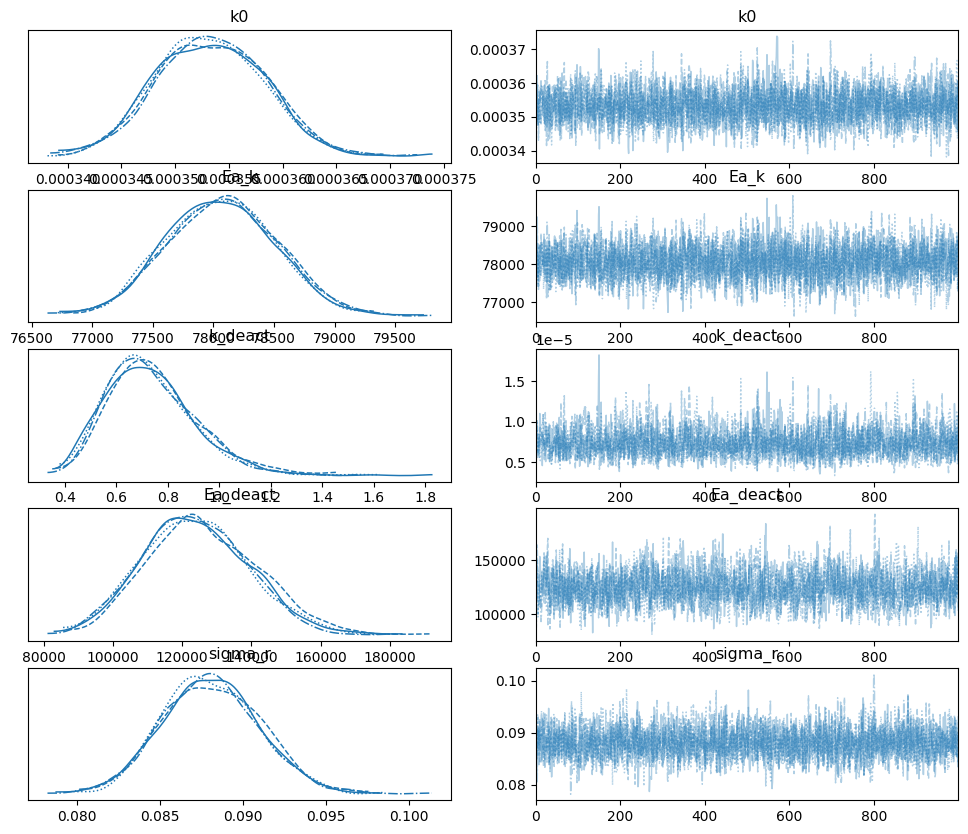

In [6]:
az.plot_trace(Mo1_idata, var_names=["k0", "Ea_k", "k_deact", "Ea_deact", "sigma_r"])

array([[<Axes: title={'center': 'k0'}>, <Axes: title={'center': 'k0'}>],
       [<Axes: title={'center': 'Ea_k'}>,
        <Axes: title={'center': 'Ea_k'}>],
       [<Axes: title={'center': 'k_deact'}>,
        <Axes: title={'center': 'k_deact'}>],
       [<Axes: title={'center': 'Ea_deact'}>,
        <Axes: title={'center': 'Ea_deact'}>],
       [<Axes: title={'center': 'sigma_r'}>,
        <Axes: title={'center': 'sigma_r'}>]], dtype=object)

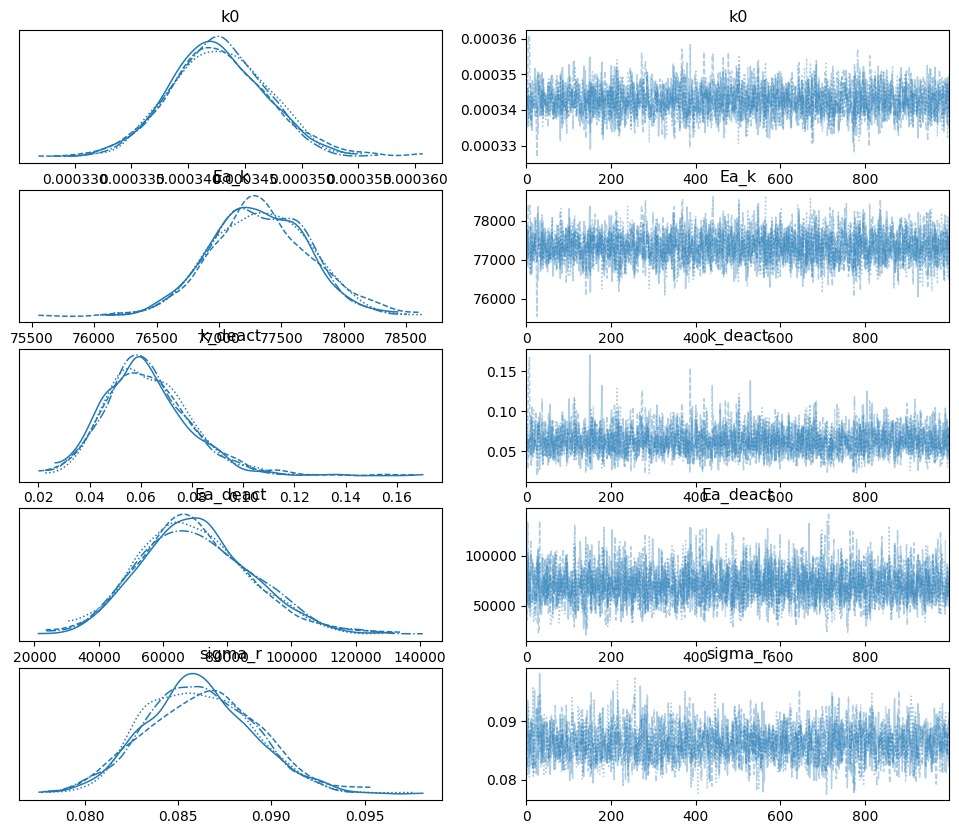

In [7]:
az.plot_trace(Mo4_idata, var_names=["k0", "Ea_k", "k_deact", "Ea_deact", "sigma_r"])

In [8]:
r_pred1 = predict_Mo1(
    Mo1_idata,
    T_obs,
    p_obs,
    num_samples=1000,
    w_noise=True,
)
r_pred2 = predict_Mo4(
    Mo4_idata,
    T_obs,
    p_obs,
    num_samples=1000,
    w_noise=True,
)

In [9]:
@interact(
    i=IntSlider(
        min=0,
        max=r_obs.shape[1] - 1,
        step=1,
        value=0,
        description="Observation Index",
    )
)
def interactive(i):
    plt.plot(r_obs[:, i, 0, 0], "ro", label="Observed data")
    plt.plot(r_pred1.mean(axis=3)[:, i, 0], label="Predicted data")
    plt.plot(r_pred2.mean(axis=3)[:, i, 0], label="Predicted data")
    plt.fill_between(
        jnp.arange(r_pred1.shape[0]),
        jnp.quantile(r_pred1[:, i, 0, :], 0.05, axis=1),
        jnp.quantile(r_pred1[:, i, 0, :], 0.95, axis=1),
        color="C0",
        alpha=0.2,
        label="90% credible interval",
    )
    plt.fill_between(
        jnp.arange(r_pred2.shape[0]),
        jnp.quantile(r_pred2[:, i, 0, :], 0.05, axis=1),
        jnp.quantile(r_pred2[:, i, 0, :], 0.95, axis=1),
        color="C1",
        alpha=0.2,
        label="90% credible interval",
    )

interactive(children=(IntSlider(value=0, description='Observation Index', max=31), Output()), _dom_classes=('w…

In [43]:
print(
    calculate_disagreement(
        idatas=[Mo1_idata, Mo4_idata],
        candidate=initial_proposals[11, :],
        num_samples=1000,
    )
)
print(
    calculate_disagreement(
        idatas=[Mo1_idata, Mo4_idata],
        candidate=initial_proposals[25, :],
        num_samples=1000,
    )
)

0.07708306
0.036832154


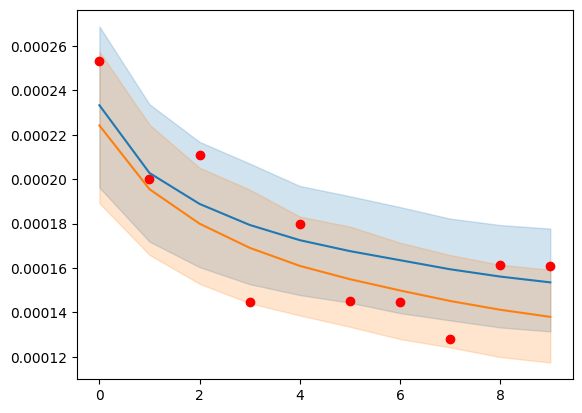

In [41]:
interactive(i=11)

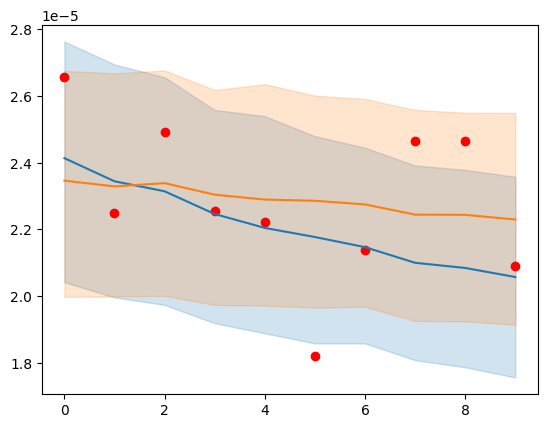

In [44]:
interactive(i=25)

In [49]:
best_parameters, metric, _, _ = find_opt_candidate(
    n_iterations=20,
    n_trials_per_iter=1,
    idatas=[Mo1_idata, Mo4_idata],
    filename="None",
)

[INFO 12-04 18:22:57] ax.api.client: GenerationStrategy(name='Center+Sobol+MBM:fast', nodes=[CenterGenerationNode(next_node_name='Sobol'), GenerationNode(name='Sobol', generator_specs=[GeneratorSpec(generator_enum=Sobol, model_key_override=None)], transition_criteria=[MinTrials(transition_to='MBM'), MinTrials(transition_to='MBM')]), GenerationNode(name='MBM', generator_specs=[GeneratorSpec(generator_enum=BoTorch, model_key_override=None)], transition_criteria=[])]) chosen based on user input and problem structure.
[INFO 12-04 18:22:57] ax.api.client: Generated new trial 0 with parameters {'T': 525.0, 'p': 6.0, 'c2h': 2.1, 'c2m': 500.25, 'c2w': 500.25, 'c2i': 0.525} using GenerationNode CenterOfSearchSpace.
[INFO 12-04 18:22:58] ax.api.client: Trial 0 marked COMPLETED.
[INFO 12-04 18:22:58] ax.api.client: Generated new trial 1 with parameters {'T': 552.852899, 'p': 4.578192, 'c2h': 0.30112, 'c2m': 936.052722, 'c2w': 192.644118, 'c2i': 0.06382} using GenerationNode Sobol.


Trial 0 has disagreement 0.0031851388048380613


[INFO 12-04 18:22:59] ax.api.client: Trial 1 marked COMPLETED.
[INFO 12-04 18:22:59] ax.api.client: Generated new trial 2 with parameters {'T': 452.056899, 'p': 7.383828, 'c2h': 2.167942, 'c2m': 498.084051, 'c2w': 916.447388, 'c2i': 0.526021} using GenerationNode Sobol.


Trial 1 has disagreement 0.027260517701506615


[INFO 12-04 18:23:00] ax.api.client: Trial 2 marked COMPLETED.
[INFO 12-04 18:23:00] ax.api.client: Generated new trial 3 with parameters {'T': 517.940022, 'p': 4.081447, 'c2h': 1.701915, 'c2m': 565.993445, 'c2w': 504.79493, 'c2i': 0.874239} using GenerationNode Sobol.


...

Trial 17 has disagreement 0.42960819602012634


[INFO 12-04 18:23:20] ax.api.client: Generated new trial 18 with parameters {'T': 450.0, 'p': 9.0, 'c2h': 0.2, 'c2m': 126.52603, 'c2w': 0.5, 'c2i': 1.0} using GenerationNode MBM.
[INFO 12-04 18:23:20] ax.api.client: Trial 18 marked COMPLETED.


Trial 18 has disagreement 0.0010351373348385096


[INFO 12-04 18:23:21] ax.api.client: Generated new trial 19 with parameters {'T': 600.0, 'p': 3.0, 'c2h': 2.556243, 'c2m': 0.5, 'c2w': 0.5, 'c2i': 0.05} using GenerationNode MBM.
[INFO 12-04 18:23:21] ax.api.client: Trial 19 marked COMPLETED.


Trial 19 has disagreement 0.4507279396057129


In [54]:
metric

{'disagreement': (np.float64(0.42014555740436654),
  np.float64(6.386504904940488e-05))}

In [51]:
next_proposal = jnp.array(
    [
        [
            best_parameters["T"],
            best_parameters["p"],
            best_parameters["c2h"],
            best_parameters["c2m"],
            best_parameters["c2w"],
            best_parameters["c2i"],
        ]
    ],
)

T = next_proposal[:, 0:1]
p = next_proposal[:, 1:2]
c2h = next_proposal[:, 2:3]
c2m = next_proposal[:, 3:4]
c2w = next_proposal[:, 4:5]
c2i = next_proposal[:, 5:6]
T_next, p_next, r_next = generate_synthetic_data(
    T,
    p,
    c2h,
    c2m,
    c2w,
    c2i,
    seed=42,
    rel_noise_std=0.1,
)

In [52]:
r_pred1_next = predict_Mo1(
    Mo1_idata,
    T_next,
    p_next,
    num_samples=1000,
    w_noise=True,
)
r_pred2_next = predict_Mo4(
    Mo4_idata,
    T_next,
    p_next,
    num_samples=1000,
    w_noise=True,
)

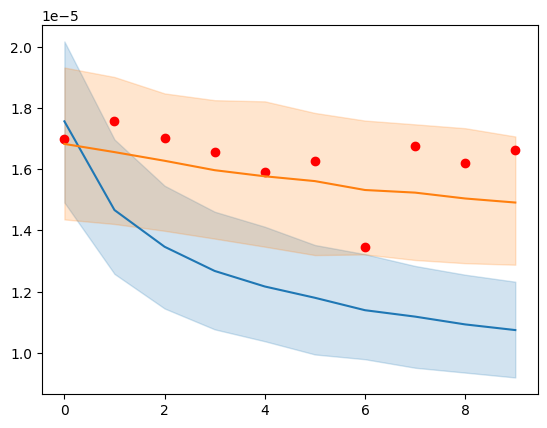

In [53]:
plt.plot(r_next[:, 0, 0, 0], "ro", label="Observed data")
plt.plot(r_pred1_next.mean(axis=3)[:, 0, 0], label="Predicted data")
plt.plot(r_pred2_next.mean(axis=3)[:, 0, 0], label="Predicted data")
plt.fill_between(
    jnp.arange(r_pred1_next.shape[0]),
    jnp.quantile(r_pred1_next[:, 0, 0, :], 0.05, axis=1),
    jnp.quantile(r_pred1_next[:, 0, 0, :], 0.95, axis=1),
    color="C0",
    alpha=0.2,
    label="90% credible interval",
)
plt.fill_between(
    jnp.arange(r_pred2_next.shape[0]),
    jnp.quantile(r_pred2_next[:, 0, 0, :], 0.05, axis=1),
    jnp.quantile(r_pred2_next[:, 0, 0, :], 0.95, axis=1),
    color="C1",
    alpha=0.2,
    label="90% credible interval",
)